# Analysis of African Architectural Content on Twitter

This notebook explores architectural themes across Africa by fetching recent tweets, performing sentiment analysis, and visualizing the accompanying media.

In [10]:
# The following are a list of architectural style , which will be used as multi-keyword search terms on X (formely twitter)

architectural_styles = [
    "vernacular african architecture",
    "traditional african architecture",
    "Indigenous african architecture",
    "mousgoum architecture",
    "mousgoum earth architecture",
    "musgum dwellings",
    "hausa architecture",
    "yoruba architecture",
    "ashanti architecture",
    "dogon architecture",
    "mossi architecture",
    "gurunsi architecture",
    "somba architecture",
    "dogon architecture",
    "batammaliba architecture",
    "swahili architecture",
    "ethiopian architecture",
    "tukul house",
    "ndebele architecture",
    "zulu architecture",
    "xhosa architecture",
    "rondavel",
    "berber architecture",
    "amazigh architecture",
    "kasbah architecture",
    "ksar architecture",
    "baka architecture",
    "Rugo compound Architecture",
    "Ancient Mud Architecture",
    "Dahomey architecture",
    "Kingdom of Dahomey",
    "Senufo architecture",
    "Zinder architecture",
    "Sudano-Sahelian architecture",
    "West African vernacular",
    "#HausaArchitecture",
    "#AfricanArchitecture",
    "#GreatZimbabwe",
    "#Djerma-Sonhay",
    "Tuareg architecture",
    "Kanuri",
    "Gurma",
    "Toubou",
    "Fulani",
    "pastoralWodaabe"

]

regions = [
    "west african architecture",
    "east african architecture",
    "southern african architecture",
    "central african architecture",
    "north african architecture"
]

materials = [
    "mud architecture",
    "earthen architecture",
    "adobe architecture",
    "rammed earth architecture",
    "thatch architecture"
]

building_types = [
    "rondavel",
    "tukul house",
    "african hut",
    "courtyard house",
    "compound architecture"
]

# The Archtetural search terms will be run as chunks to manage API call limits per search
search_keywords = list(set(architectural_styles + regions + materials + building_types))




In [9]:
import requests
import pandas as pd
import time
from google.colab import userdata

# The API used is the twitterapi.io, which doesn't limit the number of calls to thex API.
API_KEY = userdata.get("x-api-key")
headers = {"x-api-key": API_KEY}
url = "https://api.twitterapi.io/twitter/tweet/advanced_search"

def search_tweets_chunked(search_keywords, chunk_size=5, pages_per_chunk=2):
    all_tweets = []

    for i in range(0, len(search_keywords), chunk_size):
        chunk = search_keywords[i : i + chunk_size]
        query = " OR ".join([f'"{kw}"' for kw in chunk])
        print(f"Searching for chunk: {chunk}")

        cursor = None
        for page in range(pages_per_chunk):
            params = {"query": query, "count": 100}
            if cursor: params["cursor"] = cursor

            try:
                r = requests.get(url, headers=headers, params=params)
                if r.status_code != 200:
                    print(f"Error {r.status_code}: {r.text}")
                    break

                data = r.json()
                tweets = data.get("tweets", [])
                all_tweets.extend(tweets)
                print(f"  Page {page+1}: Found {len(tweets)} tweets")

                cursor = data.get("next_cursor")
                if not cursor: break
                time.sleep(1) # Rate limit safety
            except Exception as e:
                print(f"Request failed: {e}")
                break

    return all_tweets


# Run the chunked search
all_collected_tweets = search_tweets_chunked(search_keywords)

# This prints the number of tweets collected
print(f"\nTotal unique tweets collected: {len(all_collected_tweets)}")

# This removes any duplicate tweets from the collected the total collected tweets
if all_collected_tweets:
    df = pd.json_normalize(all_collected_tweets).drop_duplicates(subset=['id'])
    display(df.head())
else:
    print("No tweets were found across all keyword chunks.")

Searching for chunk: ['traditional african architecture', 'dogon architecture', 'mud architecture', 'west african architecture', 'gurunsi architecture']
  Page 1: Found 20 tweets
  Page 2: Found 20 tweets
Searching for chunk: ['hausa architecture', 'vernacular african architecture', 'thatch architecture', 'ksar architecture', 'Zinder architecture']
  Page 1: Found 20 tweets
  Page 2: Found 20 tweets
Searching for chunk: ['amazigh architecture', 'Senufo architecture', 'somba architecture', 'yoruba architecture', 'baka architecture']
  Page 1: Found 20 tweets
  Page 2: Found 20 tweets
Searching for chunk: ['north african architecture', 'West African vernacular', 'compound architecture', 'earthen architecture', 'courtyard house']
  Page 1: Found 20 tweets
  Page 2: Found 20 tweets
Searching for chunk: ['Sudano-Sahelian architecture', 'zulu architecture', 'xhosa architecture', '#AfricanArchitecture', 'rammed earth architecture']
  Page 1: Found 19 tweets
  Page 2: Found 20 tweets
Searching

,type,id,url,twitterUrl,text,source,retweetCount,replyCount,likeCount,quoteCount,...,article.title,article.preview_text,article.cover_media_img_url,quoted_tweet.card.binding_values,quoted_tweet.card.card_platform.platform.audience.name,quoted_tweet.card.card_platform.platform.device.name,quoted_tweet.card.card_platform.platform.device.version,quoted_tweet.card.name,quoted_tweet.card.url,quoted_tweet.card.user_refs_results
0,tweet,2083772278282887301,https://x.com/RealtyNXT/status/208377227828288...,https://twitter.com/RealtyNXT/status/208377227...,#Exclusive | Inside Sonam Wangchuk's Ladakh ho...,Twitter for iPhone,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,tweet,2082070349529960615,https://x.com/Mightie836/status/20820703495299...,https://twitter.com/Mightie836/status/20820703...,@deadlyfromYT @barrymc0ckner @spankbuda @__0HO...,Twitter for iPhone,0,2,22,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,tweet,2081444396772331724,https://x.com/Africanistkemte/status/208144439...,https://twitter.com/Africanistkemte/status/208...,2/2 \n\nWhat makes these mosques especially fa...,Twitter for iPhone,1,1,2,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,tweet,2078466791890714979,https://x.com/SailorJojoGames/status/207846679...,https://twitter.com/SailorJojoGames/status/207...,🎥Introducing my new sims 4 build series... get...,Twitter for iPhone,1,1,18,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,tweet,2077759475704881191,https://x.com/ericaovoke/status/20777594757048...,https://twitter.com/ericaovoke/status/20777594...,It wasn’t until last week that I began sharing...,Twitter for iPhone,7,8,28,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Raw tweets dataset**
<p> The tweets collected are saved in a CSV file "architectural_tweets.csv" <p/> <p>The total number of tweets collected from the search terms are 399.

In [13]:
# Saves the (Total unique tweets collected n=399)) to a CSV file
csv_file = 'architectural_tweets_final.csv'
df.to_csv(csv_file, index=False)
print(f"Data saved to {csv_file}")

Data saved to architectural_tweets_final.csv


**Checking the headers of the dataset**
<p> This prints a list of the headers in the dataset "architectural tweets_final.csv" <p/>

In [15]:
import pandas as pd

# Shows the headers in "architectural tweets_final.csv
try:
    df_header = pd.read_csv('architectural_tweets_final.csv')
    print("Header of 'architectural_tweets_final.csv':")
    print(df_header.columns.tolist())
except FileNotFoundError:
    print("Error: 'architectural_tweets_final.csv' not found. Please ensure the file exists.")

Header of 'architectural_tweets_final.csv':
['type', 'id', 'url', 'twitterUrl', 'text', 'source', 'retweetCount', 'replyCount', 'likeCount', 'quoteCount', 'viewCount', 'createdAt', 'lang', 'bookmarkCount', 'isReply', 'inReplyToId', 'conversationId', 'displayTextRange', 'inReplyToUserId', 'inReplyToUsername', 'quoted_tweet', 'retweeted_tweet', 'isLimitedReply', 'communityInfo', 'article', 'author.type', 'author.userName', 'author.url', 'author.twitterUrl', 'author.id', 'author.name', 'author.isVerified', 'author.isBlueVerified', 'author.verifiedType', 'author.profilePicture', 'author.coverPicture', 'author.description', 'author.location', 'author.followers', 'author.following', 'author.status', 'author.canDm', 'author.canMediaTag', 'author.createdAt', 'author.entities.description.urls', 'author.fastFollowersCount', 'author.favouritesCount', 'author.hasCustomTimelines', 'author.isTranslator', 'author.mediaCount', 'author.statusesCount', 'author.withheldInCountries', 'author.possiblySensi

**NLP to anonymise and Lemmatize the Datatset**
<p>The collected tweets are stripped of usernames and Lemmatized to remove stop words and reduce words to their base form. This reduces noise and improves analysis.

In [59]:
import pandas as pd
import re
import nltk
from nltk.stem import WordNetLemmatizer
from nltk.corpus import stopwords

# This will anonymise all tweets by removing any X usernames which start with "@"' and any leading or trailing whitespace
def anonymize_text(text):
    if not isinstance(text, str):
        return ""
    return re.sub(r'@\w+', '', text).strip()

if 'all_collected_tweets' in locals() and all_collected_tweets:
    # Use pd.json_normalize to correctly flatten the nested JSON and retain 'extendedEntities.media'
    df_new = pd.json_normalize(all_collected_tweets).drop_duplicates(subset=['id'])

    print("Anonymizing tweet text...")
    df_new['text'] = df_new['text'].apply(anonymize_text)

    # Explicitly save with all columns to avoid missing keys later
    csv_file = 'architectural_tweets_final.csv'
    df_new.to_csv(csv_file, index=False)
    print(f"Successfully saved {len(df_new)} anonymized tweets with image metadata to {csv_file}")

    nltk.download(['wordnet', 'omw-1.4', 'stopwords', 'punkt'], quiet=True)
    lemmatizer = WordNetLemmatizer()
    stop_words = set(stopwords.words('english'))

    def clean_and_lemmatize(text):
        if not isinstance(text, str):
            return ""
        text = re.sub(r'http\S+|^a-zA-Z\s]', '', text).lower()
        tokens = [lemmatizer.lemmatize(w) for w in text.split() if w not in stop_words]
        return " ".join(tokens)

    print("Lemmatizing anonymized text...")
    df_new['lemmatized_text'] = df_new['text'].apply(clean_and_lemmatize)
    display(df_new[['text', 'lemmatized_text']].head())
else:
    print("No data available in all_collected_tweets to process.")

Anonymizing tweet text...
Successfully saved 394 anonymized tweets with image metadata to architectural_tweets_final.csv
Lemmatizing anonymized text...


,text,lemmatized_text
0,#Exclusive | Inside Sonam Wangchuk's Ladakh ho...,#exclusive | inside sonam wangchuk's ladakh ho...
1,Actually these are examples of modern west Afr...,actually example modern west african architect...
2,2/2 \n\nWhat makes these mosques especially fa...,2/2 make mosque especially fascinating way arc...
3,🎥Introducing my new sims 4 build series... get...,🎥introducing new sims 4 build series... gettin...
4,It wasn’t until last week that I began sharing...,wasn’t last week began sharing post even becam...


The lemmatized dataset is save as a new CSV file 'architectural_tweets_lemmatized.csv'

```
# This is formatted as code
```



In [60]:
csv_file = 'architectural_tweets_lemmatized.csv'
df_new.to_csv(csv_file, index=False)
print(f"Data saved to {csv_file}")
print("Usernames and other identifiers were removed during the text anonymization and lemmatization steps.")

Data saved to architectural_tweets_lemmatized.csv
Usernames and other identifiers were removed during the text anonymization and lemmatization steps.


**Anonymise the usernames and tweets author names**
<p> The "architectural_tweets_lemmatized.csv" dataset was further stripped of author and twitterUrl to remove any leftover identifiers or names from the tweets  <p/>

In [61]:

# Load the lemmatized tweets CSV
df_lemmatized = pd.read_csv('architectural_tweets_lemmatized.csv')

# Identify columns to drop: 'twitterUrl' and all 'author.' columns
columns_to_drop = ['twitterUrl']
for col in df_lemmatized.columns:
    if col.startswith('author.'):
        columns_to_drop.append(col)

# Drop the identified columns
df_lemmatized_cleaned = df_lemmatized.drop(columns=columns_to_drop, errors='ignore')

# Save the modified DataFrame back to the CSV file
csv_file = 'architectural_tweets_lemmatized.csv'
df_lemmatized_cleaned.to_csv(csv_file, index=False)

print(f"Updated data saved to {csv_file} with 'twitterUrl' and 'author.' columns removed.")
display(df_lemmatized_cleaned.head())

Updated data saved to architectural_tweets_lemmatized.csv with 'twitterUrl' and 'author.' columns removed.


,type,id,url,text,source,retweetCount,replyCount,likeCount,quoteCount,viewCount,...,article.preview_text,article.cover_media_img_url,quoted_tweet.card.binding_values,quoted_tweet.card.card_platform.platform.audience.name,quoted_tweet.card.card_platform.platform.device.name,quoted_tweet.card.card_platform.platform.device.version,quoted_tweet.card.name,quoted_tweet.card.url,quoted_tweet.card.user_refs_results,lemmatized_text
0,tweet,2083772278282887301,https://x.com/RealtyNXT/status/208377227828288...,#Exclusive | Inside Sonam Wangchuk's Ladakh ho...,Twitter for iPhone,0,0,0,0,23,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,#exclusive | inside sonam wangchuk's ladakh ho...
1,tweet,2082070349529960615,https://x.com/Mightie836/status/20820703495299...,Actually these are examples of modern west Afr...,Twitter for iPhone,0,2,22,0,166,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,actually example modern west african architect...
2,tweet,2081444396772331724,https://x.com/Africanistkemte/status/208144439...,2/2 \n\nWhat makes these mosques especially fa...,Twitter for iPhone,1,1,2,0,243,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2/2 make mosque especially fascinating way arc...
3,tweet,2078466791890714979,https://x.com/SailorJojoGames/status/207846679...,🎥Introducing my new sims 4 build series... get...,Twitter for iPhone,1,1,18,1,1275,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,🎥introducing new sims 4 build series... gettin...
4,tweet,2077759475704881191,https://x.com/ericaovoke/status/20777594757048...,It wasn’t until last week that I began sharing...,Twitter for iPhone,7,8,28,0,447,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,wasn’t last week began sharing post even becam...


**Sentiment analysis of the Lemmatized text**
<p> This performs a VADER SentimentIntensityAnalyzer and calculates a compound score that categorises each tweet under a sentiment score of Positive, Neutral or Negative and stores them into a sentiment column.

In [62]:
# Ensure df_analysis is available. If not, load architectural_tweets_lemmatized.csv and perform sentiment analysis.
if 'df_analysis' not in locals() or df_analysis.empty or 'sentiment' not in df_analysis.columns:
    try:
        df_analysis = pd.read_csv('architectural_tweets_lemmatized.csv')
        # Re-run sentiment analysis if compound/sentiment columns are missing
        if 'compound' not in df_analysis.columns or 'sentiment' not in df_analysis.columns:
            import nltk
            from nltk.sentiment import SentimentIntensityAnalyzer
            import re
            nltk.download('vader_lexicon', quiet=True)
            sia = SentimentIntensityAnalyzer()

            # Runs agin to remove any trailing users name and URLs from the text, as these can interfere with sentiment scoring.
            def clean_text_for_sentiment(text):
                if isinstance(text, str):
                    text = re.sub(r'@\w+', '', text)
                    text = re.sub(r'http[s]?://(?:[a-zA-Z]|[0-9]|[$-_@.&+]|[!*\\(\),]|(?:%[0-9a-fA-F][0-9a-fA-F]))+', '', text)
                    return text.strip()
                return ""
# Calculates a compound score that categorises each tweet under a sentiment score of Positive, Neutral or Negative
            df_analysis['cleaned_text_for_sentiment'] = df_analysis['text'].apply(clean_text_for_sentiment)
            df_analysis['compound'] = df_analysis['cleaned_text_for_sentiment'].apply(lambda x: sia.polarity_scores(x)['compound'])
            df_analysis['sentiment'] = df_analysis['compound'].apply(lambda c: 'Positive' if c >= 0.05 else ('Negative' if c <= -0.05 else 'Neutral'))
            print("Sentiment analysis re-run for df_analysis.")
    except FileNotFoundError:
        print("Error: 'architectural_tweets_lemmatized.csv' not found.")
        df_analysis = pd.DataFrame()


if not df_analysis.empty and 'sentiment' in df_analysis.columns and 'text' in df_analysis.columns:
    # Set display options to show full text and wrap it
    pd.set_option('display.max_colwidth', None)
    pd.set_option('display.width', 1000) # Adjust display width for better wrapping

    sentiment_categories = ['Positive', 'Neutral', 'Negative']
    all_example_tweets = []

    print("\n--- Top 5 Example Tweets by Sentiment ---")

    for sentiment in sentiment_categories:
        example_tweets_df = df_analysis[df_analysis['sentiment'] == sentiment].head(5).copy()
        if not example_tweets_df.empty:
            example_tweets_df['sentiment_category'] = sentiment
            all_example_tweets.append(example_tweets_df[['sentiment_category', 'text']])
        else:
            print(f"\nNo {sentiment} tweets found.")

    if all_example_tweets:
        final_display_df = pd.concat(all_example_tweets)
        display(final_display_df.style.set_properties(**{'text-align': 'left', 'white-space': 'pre-wrap'}))
    else:
        print("No example tweets to display.")

    # Reset display options to default if desired after this cell
    pd.reset_option('display.max_colwidth')
    pd.reset_option('display.width')
else:
    print("Cannot display example tweets. Ensure 'architectural_tweets_lemmatized.csv' is loaded and sentiment analysis is performed.")


--- Top 5 Example Tweets by Sentiment ---


,sentiment_category,text
0,Positive,"#Exclusive | Inside Sonam Wangchuk's Ladakh home built with mud walls, passive solar heating and eco-friendly innovations. Read the full story! https://t.co/UpDSeC1bUr #RealtyNXT #SonamWangchuk #Ladakh #SustainableLiving #EcoHome #GreenArchitecture #PassiveSolar #MudHouse"
2,Positive,"2/2 What makes these mosques especially fascinating is the way their architecture combines religious requirements, environmental adaptation, and older regional building traditions. The prayer spaces retained the essential mihrab orientation toward Mecca and square congregational plans, yet features such as monumental pinnacles, sculpted façades, checkerboard ornament, geometric motifs, and carefully controlled systems of indirect illumination reveal connections with surrounding West African architecture. The article even compares certain architectural forms with Dogon and Bobo houses, sanctuaries, and mosques, noting similarities in hollow cylindrical pillars, rooftop forms, and the symbolic organization of buildings. In several Futa Toro mosques, sunlight enters through carefully positioned openings and reflects across the curved surface of the mihrab, creating small areas of illumination inside otherwise dark interiors. Rather than viewing Sudano-Sahelian mosques as isolated religious structures, the article presents them as products of centuries of interaction between Islam, local building knowledge, political history, climate, and indigenous West African concepts of architectural form and symbolism. Source: African Arts, Vol. 26, No. 3, July 1993."
3,Positive,🎥Introducing my new sims 4 build series... getting my creative juices flowing... I present ✨ reimagining traditional African hut and mud architecture✨#showusyourbuild https://t.co/rJDPP3XHka
4,Positive,"It wasn’t until last week that I began sharing posts and even became a little more proactive on X. When I subscribed, it took me so long to share posts because I wasn’t sure what I wanted to be known for. I mean.. 💠 I work as a social media manager and graphic designer. 💠 I recently dabbled in logo design. 💠 I’ve worked with a marketing team. I’ve been “X-ing,” but none of my posts even relate to any of the above. So, instead of fiddling on the digital side, I’ll be focusing on my primary interests: ❇️ Mud architecture ❇️ African furniture ❇️ & African interiors So.. I’ll be disturbing your timeline with my local-lady opinions. 🫠"
7,Positive,"Yesterday, my local artisan called to say my first rattan chair is ready. I’m actually looking at local furniture and the Nigerian interior space. This is the step I am taking towards my mud architecture dream. This space has been so “oyibonized.” Almost every house looks dull. I understand that the maximalism of Nigerian cultural designs can be overwhelming. But when done right, it is so beautiful."
1,Neutral,Actually these are examples of modern west African architecture you can find as apartments or as a hotel https://t.co/y3dyWuHH83
5,Neutral,Traditional African architecture in Burkina Faso 🇧🇫 ❤️ https://t.co/cCAyD4UdQe
6,Neutral,"Traditional African Architecture, Burkina Faso https://t.co/LPnhdVJBuX"
15,Neutral,"🏘️🇲🇱 Entre terre rouge, pierre et traditions ancestrales, les villages dogons incarnent un héritage vivant et une identité profondément enracinée #Mali #Dogon #Architecture #Culture https://t.co/lsKLJpSmUp"
16,Neutral,"🏘️🇲🇱 Entre terre, pierre et savoir-faire ancestral, les villages dogons demeurent un symbole de résilience et d’identité. � Encyclopedia Britannica +1 #Mali #Dogon #Architecture https://t.co/OOIMhdS8qd"


The Sentiment analysis table is saved to  a new CSV file 'architectural_tweets_sentiment.csv'

In [72]:
csv_file_sentiment = 'architectural_tweets_sentiment.csv'
df_analysis.to_csv(csv_file_sentiment, index=False)
print(f"Sentiment analysis data saved to {csv_file_sentiment}")

Sentiment analysis data saved to architectural_tweets_sentiment.csv


# 3. Sentiment Analysis
The analysed sentimements are plotterd into a bar chart for easy visualisation of the sentiment distribution

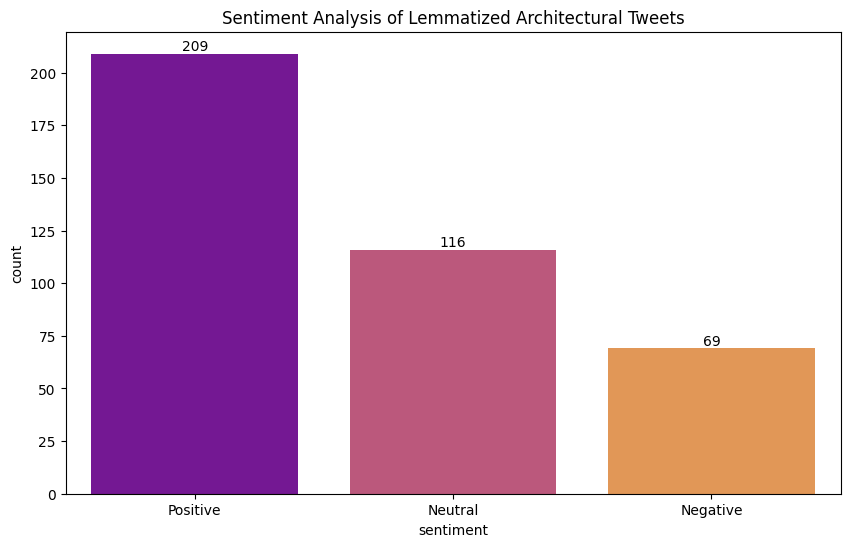

In [63]:
from nltk.sentiment import SentimentIntensityAnalyzer
import seaborn as sns
import matplotlib.pyplot as plt

nltk.download('vader_lexicon', quiet=True)
sia = SentimentIntensityAnalyzer()

# Perform Sentiment Analysis on the newly lemmatized column
df_new['compound'] = df_new['lemmatized_text'].apply(lambda x: sia.polarity_scores(x)['compound'])
df_new['sentiment'] = df_new['compound'].apply(lambda c: 'Positive' if c >= 0.05 else ('Negative' if c <= -0.05 else 'Neutral'))

# Visualize the distribution
plt.figure(figsize=(10, 6))
ax = sns.countplot(data=df_new, x='sentiment', palette='plasma', hue='sentiment', legend=False)
plt.title('Sentiment Analysis of Lemmatized Architectural Tweets')

# Add numbers above each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%d')

plt.show()

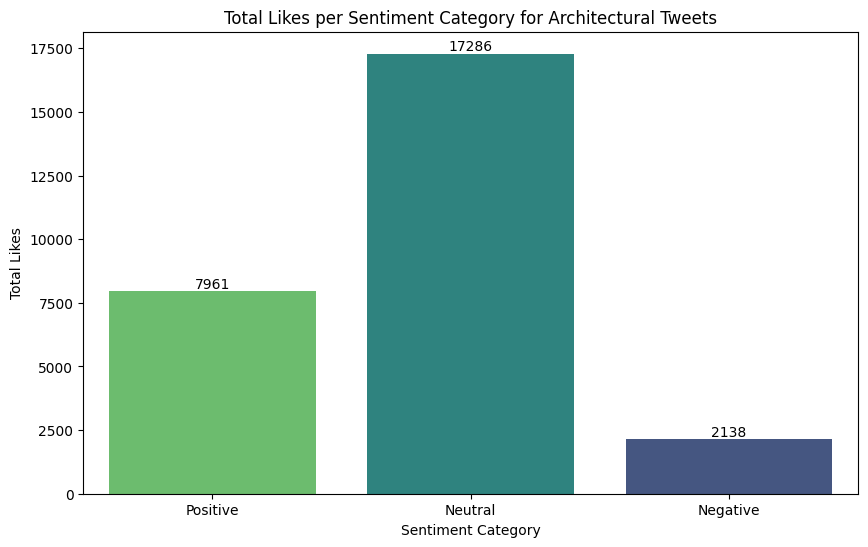

In [64]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate total likes per sentiment category
likes_per_sentiment = df_new.groupby('sentiment')['likeCount'].sum().reset_index()

# Define the desired order of sentiments
sentiment_order = ['Positive', 'Neutral', 'Negative']

# Visualize the total likes per sentiment with the specified order
plt.figure(figsize=(10, 6))
ax = sns.barplot(data=likes_per_sentiment, x='sentiment', y='likeCount', palette='viridis', hue='sentiment', legend=False, order=sentiment_order)
plt.title('Total Likes per Sentiment Category for Architectural Tweets')
plt.xlabel('Sentiment Category')
plt.ylabel('Total Likes')

# Add numbers above each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%d')

plt.show()

### Top 3 Tweets by Like Count for Each Sentiment Category

In [65]:

# Set display options to show full text and wrap it
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 1000) # Adjust display width for better wrapping

top_tweets_by_sentiment = []
sentiment_categories = ['Positive', 'Neutral', 'Negative']

for sentiment in sentiment_categories:
    # Filter by sentiment, sort by likeCount, and get the top 3
    top_3_tweets = df_new[df_new['sentiment'] == sentiment].nlargest(3, 'likeCount')
    if not top_3_tweets.empty:
        top_tweets_by_sentiment.append(top_3_tweets[['sentiment', 'text', 'likeCount']])

if top_tweets_by_sentiment:
    # Concatenate the results into a single DataFrame for display
    final_top_tweets_df = pd.concat(top_tweets_by_sentiment)
    display(final_top_tweets_df.style.set_properties(**{'text-align': 'left', 'white-space': 'pre-wrap'}))
else:
    print("No tweets found to display for the top likes per sentiment category.")

# Reset display options to default after this cell
pd.reset_option('display.max_colwidth')
pd.reset_option('display.width')

,sentiment,text,likeCount
103,Positive,"🇩🇿 Standing near the city of Batna in Algeria and dating back to the 3rd century BCE, Madghacen is the oldest and most magnificent ancient royal mausoleum in North Africa, featuring a massive stone tumulus with a diameter of 58.9 meters and a height of 18.5 meters. Believed to have been built for the Numidian Kings, particularly King Madghis, this monumental structure presents a unique synthesis of traditional Berber/Amazigh architecture and Hellenistic influences with its surrounding 60 Doric columns. Symbolizing the engineering prowess and political might of the Numidian civilization long before Roman dominance, the mausoleum is currently on the UNESCO World Heritage Tentative List; however, despite facing a serious risk of collapse due to natural erosion and neglect, it continues to endure at the foothills of the Aures Mountains as the most powerful silent witness to the region's ancient history.",877
304,Positive,"The Hausa are the largest ethnic group in West and Central Africa, known for their diverse but culturally homogeneous population. Their traditional architecture remains influential in Africa, characterized by vaults, decorative walls, and vibrant motifs. #HausaArchitecture https://t.co/UVu8kMRTJG",521
105,Positive,"Aït Benhaddou - Morocco 🇲🇦 Aït Benhaddou, a UNESCO World Heritage site, was built at a strategic location to provide a secure stop for caravans on the Trans-Saharan trade route; while most of the current structures date back to the 17th century, the settlement's origins go back much further. As one of the most unique examples of traditional Amazigh architecture, this historic fortified village serves today as a massive natural film set, having hosted many iconic productions such as Gladiator, Lawrence of Arabia, and The Mummy.",494
230,Neutral,"Her name was Àbáké. She was Yoruba, from a village in West Africa raided by the Kingdom of Dahomey. Captured at ~2 years old, she was marched to Ouidah (Benin) and brought to Alabama on the Clotilda.",6282
75,Neutral,"This is not Nigerian architecture. It is Hausa architecture. Please,don't nigerianize their culture",2758
334,Neutral,"I am Adjepong Akua Owusua. An architectural designer and I travel around Ghana documenting indegenous buildings and construction. On my visit to Ashanti region, I visited the yaw Tano shrine in Ejisu Bease , one of the remaining Ashanti architecture https://t.co/ucwJXnSfIw",2668
256,Negative,Internet propaganda has made African hut dwellers believe that they're on the same level as India. https://t.co/OD0jdIZkP7,657
31,Negative,"These discussions are so dumb, “oh they’re low iq?! What about this ancient tablet, what about the mud architecture in Timbuktu what about blah blah blah.” The black guy at the end of my street can’t read. You’re not gonna convince me they’re smart with some academic bullshit.",320
156,Negative,"meta muse spark 1.1 vs gpt 5.6 sol vs fable 5 vs grok 4.5 meta recently dropped muse spark 1.1 – a multimodal reasoning model from meta superintelligence labs built for agentic tasks. key facts: • 1m token context with active self-management – the model compacts its own history and keeps only the steps needed for later work • trained to orchestrate multi-agent systems: as main agent it plans and delegates to parallel subagents, as subagent it sticks to its job and knows when to escalate back • computer use trained to pick between scripting and clicking – writes automation when it's faster, clicks when it's simpler, batches actions per step • first public api from meta: the meta model api is now in preview • benchmarks: sweeps the agent column – mcp atlas 88.1 (opus 4.8: 82.2), jobbench 54.7 (opus: 48.4), humanity's last exam 62.1 (1st). loses coding – deepswe 1.1 53.3 vs gpt 5.5's 67.0, swe bench pro 61.5 vs opus's 69.2 our test – 3 prompts, single-file html, three.js, fully procedural, no assets: 1. norwegian house cantilevered over a fjord in a snowstorm – transmissive glass

**Hexagonal Image Grid**
  <p>The hexagonal image grid shows some of the images that were shared in the analysed tweets. A few of them show non-architectural subject matter, with even fewer of them showing traditional African architecture. The shared images were cropped into hexagons and arranged into a grid for easier comparison between different image aspect ratios.

Dataset 'architectural_tweets_final.csv' loaded successfully.
Displaying 386 unique images from 'architectural_tweets_final.csv'.
Hexagonal gallery saved as 'hexagonal_architectural_gallery.png'


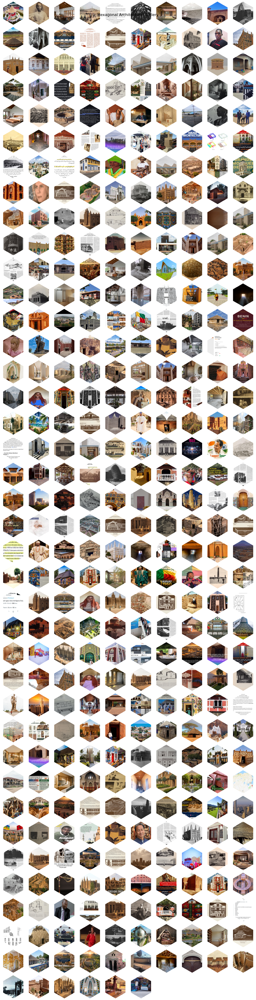

In [66]:
from IPython.display import display, Image, HTML
import matplotlib.pyplot as plt
import math
from PIL import Image as PILImage, ImageDraw
import requests
import numpy as np
import pandas as pd
import ast

def create_hex_mask(size):
    width, height = size
    mask = PILImage.new('L', size, 0)
    draw = ImageDraw.Draw(mask)
    center_x, center_y = width / 2, height / 2
    hex_radius = min(width, height) / 2
    angle_offset = np.pi / 6
    hex_vertices = []
    for i in range(6):
        x = center_x + hex_radius * np.cos(angle_offset + i * np.pi / 3)
        y = center_y + hex_radius * np.sin(angle_offset + i * np.pi / 3)
        hex_vertices.append((x, y))
    draw.polygon(hex_vertices, fill=255)
    return mask

# Load the dataset from 'architectural_tweets_final.csv' (which contains media info)
try:
    df_gallery_source = pd.read_csv('architectural_tweets_final.csv')
    print("Dataset 'architectural_tweets_final.csv' loaded successfully.")
except FileNotFoundError:
    print("Error: 'architectural_tweets_final.csv' not found. Please ensure the file exists.")
    df_gallery_source = pd.DataFrame()

if not df_gallery_source.empty:
    # Correct column name for media entities
    img_col = 'extendedEntities.media'

    if img_col in df_gallery_source.columns:
        def extract_media_urls(val):
            urls = []
            if pd.isna(val): # Handle NaN values
                return []
            if isinstance(val, str):
                try:
                    media_list = ast.literal_eval(val)
                    if isinstance(media_list, list):
                        for media_item in media_list:
                            if isinstance(media_item, dict) and 'media_url_https' in media_item:
                                urls.append(media_item['media_url_https'])
                except (ValueError, SyntaxError) as e:

                    pass
            elif isinstance(val, list): # If it's already a list of dicts
                for media_item in val:
                    if isinstance(media_item, dict) and 'media_url_https' in media_item:
                        urls.append(media_item['media_url_https'])
            return urls

        all_image_urls = []
        for media_data in df_gallery_source[img_col].apply(extract_media_urls):
            all_image_urls.extend(media_data)

        unique_images_for_grid = list(set(all_image_urls))

        if unique_images_for_grid:
            print(f"Displaying {len(unique_images_for_grid)} unique images from 'architectural_tweets_final.csv'.")
            uniform_image_size = (128, 128)
            cols = 10
            rows = math.ceil(len(unique_images_for_grid) / cols)
            hex_mask = create_hex_mask(uniform_image_size)

            fig = plt.figure(figsize=(15, rows * 1.5))
            for i, img_url in enumerate(unique_images_for_grid):
                ax = fig.add_subplot(rows, cols, i + 1)
                try:
                    # Add a timeout to prevent hanging on bad URLs
                    response = requests.get(img_url, stream=True, timeout=5)
                    img = PILImage.open(response.raw).convert('RGBA')
                    img = img.resize(uniform_image_size, PILImage.LANCZOS)
                    img.putalpha(hex_mask)
                    ax.imshow(img)
                except Exception as e:
                    # Print error for debugging, but display 'N/A' gracefully
                    # print(f"Could not load image {img_url}: {e}") # Uncomment for debugging image loading errors
                    ax.text(0.5, 0.5, 'N/A', ha='center', va='center', fontsize=8, color='red')
                ax.axis('off')
            plt.suptitle('Hexagonal Architectural Gallery', fontsize=16)
            plt.tight_layout()

            # Save the figure as an image file
            plt.savefig('hexagonal_architectural_gallery.png', bbox_inches='tight', dpi=300)
            print("Hexagonal gallery saved as 'hexagonal_architectural_gallery.png'")

            plt.show()
        else:
            print("No valid image URLs found in 'architectural_tweets_final.csv' to display.")
    else:
        print(f"Error: Column '{img_col}' not found in 'architectural_tweets_final.csv'. Please ensure the file contains an '{img_col}' column.")
else:
    print("Cannot create gallery as the DataFrame is empty or could not be loaded.")